<br>
<a href="https://github.com/aperture-systems-lab">
    <img src="assets/banner_semillero.png" width="955" style="margin: 0px 0px 12px;"/>
</a>
<h1 style="line-height: 1.4;"><font color="#29c4d9"><b>De Prompts a Agentes:</b></font> Inteligencia Artificial Agéntica con Python</h1>
<h2><b>Notebook 3: </b>MCP, multimodal y LangGraph</h2>
<br>

In [170]:
from dotenv import load_dotenv

load_dotenv()

True

In [171]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage

modelo = init_chat_model("google_genai:gemini-3.6-flash")

----

<br>

## **Parte 1:** MCP

<img src="assets/diagramas/mcp.png" width="760"/>

In [172]:
import sys

sys.stderr = sys.__stderr__  # en Jupyter (sobre todo en Windows) el servidor MCP necesita la stderr real

In [173]:
from langchain_mcp_adapters.client import MultiServerMCPClient

cliente = MultiServerMCPClient({
    "senor_gato": {
        "transport": "stdio",
        "command": sys.executable,
        "args": ["servidor_mcp.py"],
    }
})

herramientas = await cliente.get_tools()

for herramienta in herramientas:
    print(f"{herramienta.name}: {herramienta.description}")

cuota_credito: Calcula la cuota mensual de un crédito hipotecario en pesos colombianos.
gastos_de_cierre: Estima en pesos los gastos de notaría, registro y beneficencia de una compra.


In [174]:
recursos = await cliente.get_resources("senor_gato")
print(recursos[0].as_string())

Banco Nutibara: 11,8 % E.A.
Banco La Montaña: 12,4 % E.A.
Cooperativa Gatuna: 11,2 % E.A.


In [175]:
prompt = await cliente.get_prompt("senor_gato", "asesor_financiero", arguments={"cliente": "Laura"})
print(prompt[0].content)

Eres el asesor financiero de la Inmobiliaria Señor Gato y atiendes a Laura. Haz las cuentas con tus herramientas, nunca de memoria. Escribe los valores en pesos con puntos de miles, por ejemplo $2.816.000, y responde en pocas líneas.


In [176]:
agente = create_agent(modelo, tools=herramientas, system_prompt=prompt[0].content)

respuesta = await agente.ainvoke({"messages": [HumanMessage(
    "Quiero el SG-101, que cuesta 380 millones. ¿Cuánto pagaría al mes con 30 % de cuota inicial a 20 años? ¿Y de gastos de cierre?"
)]})

for mensaje in respuesta["messages"]:
    mensaje.pretty_print()

================================ Human Message =================================

Quiero el SG-101, que cuesta 380 millones. ¿Cuánto pagaría al mes con 30 % de cuota inicial a 20 años? ¿Y de gastos de cierre?
================================== Ai Message ==================================

[]
Tool Calls:
  cuota_credito (call_4584380802717878979)
 Call ID: call_4584380802717878979
  Args:
    cuota_inicial_pct: 30
    precio: 380000000
    anios: 20
  gastos_de_cierre (call_4584380802717878948)
 Call ID: call_4584380802717878948
  Args:
    precio: 380000000
================================= Tool Message =================================
Name: cuota_credito

[{'type': 'text', 'text': '{\n  "cuota_inicial": 114000000,\n  "prestamo": 266000000,\n  "cuota_mensual": 2815938,\n  "meses": 240,\n  "tasa_anual_pct": 12.0\n}', 'id': 'lc_20de3576-38ba-414e-9f15-42353672e125'}]
================================= Tool Message =================================
Name: gastos_de_cierre

[{'type': 'text

----

<br>

## **Parte 2:** Multimodal

<img src="assets/diagramas/multimodal.png" width="760"/>

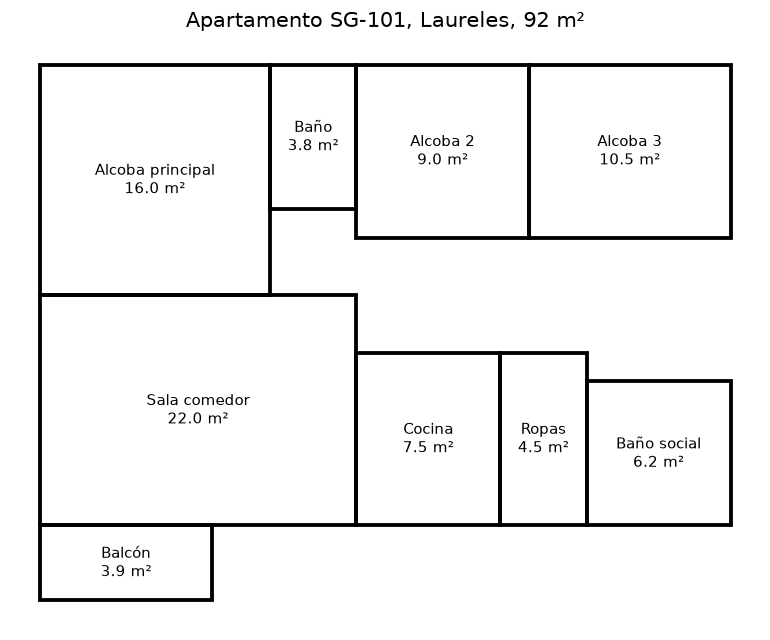

In [177]:
import base64

from IPython.display import Image


def en_base64(ruta):
    with open(ruta, "rb") as archivo:
        return base64.b64encode(archivo.read()).decode()


Image("datos/plano_sg101.png", width=450)

In [178]:
mensaje = HumanMessage(content=[
    {"type": "text", "text": "¿Cuántas alcobas y cuántos baños tiene este plano? ¿Cuál es la alcoba más grande?"},
    {"type": "image", "base64": en_base64("datos/plano_sg101.png"), "mime_type": "image/png"},
])

print(modelo.invoke([mensaje]).text)

Basándonos en el plano, aquí están las respuestas a tus preguntas:

1. **Número de alcobas:** Tiene **3 alcobas** (Alcoba principal, Alcoba 2 y Alcoba 3).
2. **Número de baños:** Tiene **2 baños** (un baño de 3.8 m² y un baño social de 6.2 m²).
3. **Alcoba más grande:** La **Alcoba principal**, con un área de **16.0 m²**.


----

<br>

## **Parte 3:** LangGraph

<img src="assets/diagramas/grafo_minimo.png" width="760"/>

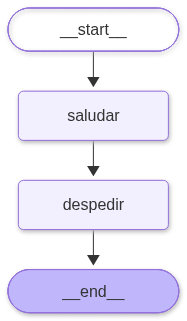

In [179]:
from typing import TypedDict

from langgraph.graph import END, START, StateGraph


class Saludo(TypedDict):
    texto: str


def saludar(estado: Saludo):
    return {"texto": estado["texto"] + " ¡Hola!"}


def despedir(estado: Saludo):
    return {"texto": estado["texto"] + " Chao, pues."}


grafo = StateGraph(Saludo)
grafo.add_node("saludar", saludar)
grafo.add_node("despedir", despedir)
grafo.add_edge(START, "saludar")
grafo.add_edge("saludar", "despedir")
grafo.add_edge("despedir", END)

app = grafo.compile()

Image(app.get_graph().draw_mermaid_png())

In [180]:
app.invoke({"texto": "Señor Gato dice:"})

{'texto': 'Señor Gato dice: ¡Hola! Chao, pues.'}

Una **arista condicional** decide qué nodo sigue según el estado.

<img src="assets/diagramas/publicar.png" width="760"/>

In [ ]:
from langchain.messages import AIMessage, SystemMessage
from langgraph.graph import MessagesState
from pydantic import BaseModel, Field


class Ficha(BaseModel):
    barrio: str | None
    alcobas: int | None
    banos: int | None
    precio_millones: int | None = Field(description="Precio de venta en millones de pesos")

In [ ]:
BIENVENIDA = "Hola, para publicar tu apartamento cuéntame el barrio, cuántas alcobas y baños tiene y en cuánto lo vendes."


def bienvenida(estado: MessagesState):
    print(f"Agente: {BIENVENIDA}")
    return {"messages": [AIMessage(BIENVENIDA)]}


def recibir(estado: MessagesState):
    respuesta = input("Usuario: ")
    print(f"Usuario: {respuesta}")
    return {"messages": [HumanMessage(respuesta)]}


def pedir(estado: MessagesState):
    pregunta = modelo.invoke([
        SystemMessage("""Para publicar un apartamento hacen falta:
    - barrio
    - alcobas
    - baños
    - precio

Pide en una línea lo que falte."""),
        *estado["messages"],
    ])
    print(f"Agente: {pregunta.text}")
    return {"messages": [pregunta]}


def publicar(estado: MessagesState):
    anuncio = modelo.invoke([
        SystemMessage("""Escribe el anuncio para la página web.
    - Usa los datos que dio el dueño.
    - Máximo tres líneas."""),
        *estado["messages"],
    ])
    return {"messages": [anuncio]}

In [ ]:
def decidir(estado: MessagesState):
    ficha = modelo.with_structured_output(Ficha).invoke(estado["messages"])
    faltan = [dato for dato, valor in ficha.model_dump().items() if valor is None]
    print(f"faltan: {faltan}")
    if faltan:
        return "pedir"
    return "publicar"

In [ ]:
grafo = StateGraph(MessagesState)
grafo.add_node("bienvenida", bienvenida)
grafo.add_node("recibir", recibir)
grafo.add_node("pedir", pedir)
grafo.add_node("publicar", publicar)

grafo.add_edge(START, "bienvenida")
grafo.add_edge("bienvenida", "recibir")
grafo.add_conditional_edges("recibir", decidir, ["pedir", "publicar"])  # ¿falta algo?
grafo.add_edge("pedir", "recibir")
grafo.add_edge("publicar", END)

publicador = grafo.compile()

Image(publicador.get_graph().draw_mermaid_png())

**Caso 1: por partes.** El modelo pregunta hasta tener todo.
1. Queda en Laureles y tiene 3 alcobas.
2. Tiene 2 baños.
3. Lo vendo en 380 millones.

**Caso 2: todo en una respuesta.** El grafo publica con la primera respuesta.
1. Queda en Belén, 2 alcobas, 1 baño, 295 millones.

In [ ]:
resultado = publicador.invoke({"messages": []})
print("Anuncio:", resultado["messages"][-1].text)

-----

<br>

### **Siguiente notebook:**

[`04_patrones.ipynb`](04_patrones.ipynb)

### <font color="#29c4d9">**Notebook 3 listo.**</font>

<br>

---
<div style="margin-top: 50px;"><center><a href="https://github.com/aperture-systems-lab"><img src="assets/banner_logo.png" width="955"/></a></center></div>